In [1]:
%load_ext autoreload
%autoreload 2

auto reload en cas de modif du socle pour éviter de recharger le noyau a chaque fois

## Etape 1:

Mise en place : socle src/ml (bibliothèque du TP 14), export, train, plis, empreintes des jumeaux  
SHA-256 : 88f78e534cb0770c22d564237d3d536a4414285bdc9267a8bdff76816ecb4d8c

In [2]:
import pandas as pd

from src import config
from src.ml.evaluation import evaluate_model, fingerprint, make_cv
from src.ml.features import features_and_target, load_features, split_train_test
from src.ml.modeling import RANDOM_STATE, build_pipeline, check_no_leak
from src.storage.export_features import EXPORT_PREFIX
from src.utils import find_input

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

# Export le plus récent, nommé explicitement : il doit être celui des résultats finaux du TP 14
export_path = find_input(config.EXPORTS_DIR, EXPORT_PREFIX, ".parquet")
df = load_features(export_path)

# Seul le train est extrait : le test n'apparaîtra qu'après toutes les décisions du TP
train, _ = split_train_test(df)
X_train, y_train = features_and_target(train)
check_no_leak(build_pipeline(None), X_train)

cv = make_cv()                                # un seul objet de plis, partagé par tous les modèles
train_fingerprints = fingerprint(X_train)     # empreintes calculées une fois, pour la mesure sans jumeau

print(f"Export : {export_path.name} ({len(df):,} produits)".replace(",", " "))
print(f"Train : {len(X_train):,} produits, {X_train.shape[1]} features".replace(",", " "))

Export : features_nutriscore_20261121.parquet (459 558 produits)
Train : 367 646 produits  13 features


réentraînement des modèles du TP 14 (logistique et forêt brutes), point de contrôle 1

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

N_JOBS = -1   # coeurs pour les modèles qui le permettent ; à baisser si la mémoire sature

# Chiffres du TP 14, produits par le code du journal tp14.ipynb (F1 macro : cellule 15 ; sans jumeau : cellules 18 et 19)
TP14_REFERENCE = {
    "logistic_regression": {"f1_macro_mean": 0.7675, "f1_macro_std": 0.0019, "f1_macro_without_twin_mean": 0.7506},
    "random_forest": {"f1_macro_mean": 0.9120, "f1_macro_std": 0.0006, "f1_macro_without_twin_mean": 0.8887},
}

models = {
    "logistic_regression": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),   # multinomiale par défaut
    "random_forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS),
}

results, oof = {}, {}
for name, model in models.items():
    results[name], oof[name] = evaluate_model(build_pipeline(model), X_train, y_train, cv, train_fingerprints)
    print(f"{name} : terminé")

# Comparaison au TP 14 : écart toléré 0,01 (point de contrôle 1)
comparison = pd.DataFrame([
    {
        "model": name,
        "tp14_f1_macro": TP14_REFERENCE[name]["f1_macro_mean"],
        "tp15_f1_macro": results[name]["f1_macro_mean"],
        "gap": results[name]["f1_macro_mean"] - TP14_REFERENCE[name]["f1_macro_mean"],
        "tp14_without_twin": TP14_REFERENCE[name]["f1_macro_without_twin_mean"],
        "tp15_without_twin": results[name]["f1_macro_without_twin_mean"],
        "gap_without_twin": results[name]["f1_macro_without_twin_mean"] - TP14_REFERENCE[name]["f1_macro_without_twin_mean"],
    }
    for name in models
]).set_index("model")
display(comparison)

max_gap = comparison[["gap", "gap_without_twin"]].abs().to_numpy().max()
print(f"Point de contrôle 1 (écart <= 0,01) : {'validé' if max_gap <= 0.01 else 'NON validé : la préparation a changé'} "
      f"(écart max {max_gap:.4f})")

logistic_regression : terminé
random_forest : terminé


,tp14_f1_macro,tp15_f1_macro,gap,tp14_without_twin,tp15_without_twin,gap_without_twin
model,,,,,,
logistic_regression,0.7675,0.7676,7.0329e-05,0.7506,0.7506,-2.2962e-05
random_forest,0.9120,0.9119,-1.0955e-04,0.8887,0.8885,-1.5832e-04


Point de contrôle 1 (écart <= 0,01) : validé (écart max 0.0002)


bibliothèques de boosting et de réglage disponibles, avec leur version

In [4]:
from importlib.metadata import PackageNotFoundError, version

import sklearn

# Versions citées par l'énoncé du TP 15 (environnement de référence)
EXPECTED = {"xgboost": "3.4", "lightgbm": "4.7", "catboost": "1.2", "optuna": "5"}

print(f"scikit-learn : {sklearn.__version__} (HistGradientBoostingClassifier inclus)")
for package, expected in EXPECTED.items():
    try:
        installed = version(package)
        status = "conforme" if installed.startswith(expected) else f"énoncé : {expected}.x"
        print(f"{package} : {installed} ({status})")
    except PackageNotFoundError:
        print(f"{package} : NON INSTALLÉ (énoncé : {expected}.x)")

scikit-learn : 1.9.1 (HistGradientBoostingClassifier inclus)
xgboost : 3.4.1 (conforme)
lightgbm : 4.7.0 (conforme)
catboost : NON INSTALLÉ (énoncé : 1.2.x)
optuna : 5.0.0 (conforme)


cible codée en entiers 0 à 4

In [5]:
from src.ml.features import GRADE_CODES, decode_target, encode_target

y_train_codes = encode_target(y_train)   # XGBoost exige des entiers ; les métriques sont inchangées

print(f"Codage : {GRADE_CODES}")
print(pd.DataFrame({"grade": y_train, "code": y_train_codes}).drop_duplicates().sort_values("code").to_string(index=False))

Codage : {'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4}
grade  code
    a     0
    b     1
    c     2
    d     3
    e     4


Trois boosters avec leurs réglages par défaut (mêmes préparation, plis, métriques, cible codée)

In [6]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

boosters = {
    "hist_gradient_boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "xgboost": XGBClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS),
    "lightgbm": LGBMClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1),
}

for name, model in boosters.items():
    results[name], oof[name] = evaluate_model(build_pipeline(model), X_train, y_train_codes, cv, train_fingerprints)
    print(f"{name} : terminé")

# Tableau provisoire : modèles du TP 14 (étape 1) et boosters par défaut
summary_columns = ["f1_macro_mean", "f1_macro_std", "f1_macro_without_twin_mean", "f1_macro_without_twin_std",
                   "fit_time_s_mean", "predict_time_s_mean"]
step2_table = pd.DataFrame(results).T[summary_columns].sort_values("f1_macro_mean")
display(step2_table)

hist_gradient_boosting : terminé
xgboost : terminé
lightgbm : terminé


,f1_macro_mean,f1_macro_std,f1_macro_without_twin_mean,f1_macro_without_twin_std,fit_time_s_mean,predict_time_s_mean
logistic_regression,0.7676,0.0015,0.7506,0.0014,24.6636,0.0762
lightgbm,0.9093,0.0007,0.8920,0.0010,16.7161,0.1886
random_forest,0.9119,0.0008,0.8885,0.0012,5.4581,0.2113
hist_gradient_boosting,0.9203,0.0067,0.9052,0.0076,7.2668,0.2082
xgboost,0.9309,0.0004,0.9167,0.0007,16.9293,0.1134


Modèle choisis : HistGradientBoosting. Le plus rapide des boosters (7,5 s par pli) et doté d’un arrêt précoce intégré, il est le seul à tenir un budget de 30 essais en un quart d’heure ; son score par défaut (0,921) est proche du meilleur, XGBoost (0,931), que ses ~22 s pour 100 arbres rendraient trop lent à régler.

#### Réglage de HistGradientBoosting — budget annoncé avant lancement

Budget : 30 essais Optuna, 3 plis, MedianPruner, environ 15 minutes attendues (garde-fou : arrêt à 20 minutes).

- Critère : F1 macro sans jumeau, moyenne sur 3 plis ("StratifiedKFold(3, shuffle=True, random_state=42)"),
  pour récompenser la généralisation plutôt que la mémorisation des jumeaux.
- Pruning : le score est rapporté après chaque pli ; un essai nettement sous la médiane des essais précédents
  est arrêté avant ses 3 plis.
- Estimation : ~6 s par ajustement à 100 itérations (7,5 s mesurées à 5 plis, sur 4/5 du train ; ici 2/3 du train).
  Avec l'arrêt précoce, un essai à petit pas d'apprentissage peut compter plusieurs centaines d'itérations ;
  moyenne supposée ~15 s par ajustement, soit ~45 s par essai, ~22 min sans pruning, ~15 min avec.
  Estimation incertaine : le temps réel est mesuré et noté après la recherche.

Espace de recherche (5 hyperparamètres) :

| Hyperparamètre | Plage | Justification |
|---|---|---|
| "learning_rate" | 0,03 – 0,3 (log) | taille de chaque correction : petit = plus d'arbres, plus lent ; plancher à 0,03 pour tenir le budget |
| "max_leaf_nodes" | 15 – 127 (log) | complexité de chaque arbre (31 par défaut) |
| "min_samples_leaf" | 10 – 200 (log) | taille minimale d'une feuille : freine la mémorisation des cas isolés |
| "l2_regularization" | 0,001 – 10 (log) | pénalité qui lisse les corrections |
| "class_weight" | aucun / "balanced" | traitement du déséquilibre, retenu pour la forêt au TP 14 |

Fixés : "max_iter=1200" (plafond du dépannage), arrêt précoce activé ("early_stopping=True",
"n_iter_no_change=10") : le nombre d'arbres est choisi par l'arrêt précoce, pas par la recherche.

Réglage de HistGradientBoosting, budget annoncé, temps réel mesuré, optimisation des réglages grace à optuna  

code commenté pour éviter la ré-éxécution, le code a remplis son role on garde l'output

In [9]:
import time

import numpy as np
import optuna
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

from src.ml.evaluation import METRICS

N_TRIALS = 30
TIMEOUT_S = 20 * 60   # garde-fou : la recherche s'arrête à la fin de l'essai en cours après 20 minutes
SEARCH_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search_folds = list(SEARCH_CV.split(X_train, y_train_codes))   # 3 plis de recherche, calculés une fois
f1_macro = METRICS["f1_macro"]


def objective(trial: optuna.Trial) -> float:
    """F1 macro sans jumeau, moyen sur les 3 plis de recherche ; arrêt anticipé si l'essai est sous la médiane."""
    model = HistGradientBoostingClassifier(
        learning_rate=trial.suggest_float("learning_rate", 0.03, 0.3, log=True),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 15, 127, log=True),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 10, 200, log=True),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 10, log=True),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        max_iter=1200, early_stopping=True, n_iter_no_change=10, random_state=RANDOM_STATE,
    )
    scores_without_twin, scores_all = [], []
    for step, (train_idx, val_idx) in enumerate(search_folds):
        pipeline = build_pipeline(clone(model)).fit(X_train.iloc[train_idx], y_train_codes.iloc[train_idx])
        y_val, y_pred = y_train_codes.iloc[val_idx], pipeline.predict(X_train.iloc[val_idx])
        has_twin = train_fingerprints.iloc[val_idx].isin(set(train_fingerprints.iloc[train_idx])).to_numpy()

        scores_without_twin.append(f1_macro(y_val[~has_twin], y_pred[~has_twin]))
        scores_all.append(f1_macro(y_val, y_pred))
        trial.report(np.mean(scores_without_twin), step)
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("f1_macro_all", float(np.mean(scores_all)))   # chiffre sur tous les produits, pour mémoire
    return float(np.mean(scores_without_twin))


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5),
)

start = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_S)
search_minutes = (time.perf_counter() - start) / 60

states = pd.Series([trial.state.name for trial in study.trials]).value_counts().to_dict()
print(f"Temps réel : {search_minutes:.1f} min (annoncé : ~15 min) ; essais : {states}")
print(f"Meilleur F1 macro sans jumeau (3 plis) : {study.best_value:.4f}")
print(f"Meilleurs réglages : {study.best_params}")

study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "duration", "state")) \
     .sort_values("value", ascending=False).head(10)

/home/choco/Projets/nutri_private/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Temps réel : 21.5 min (annoncé : ~15 min) ; essais : {'COMPLETE': 8, 'PRUNED': 4}
Meilleur F1 macro sans jumeau (3 plis) : 0.9361
Meilleurs réglages : {'learning_rate': 0.08574153197420807, 'max_leaf_nodes': 80, 'min_samples_leaf': 17, 'l2_regularization': 0.11400863701127326, 'class_weight': None}


,number,value,params_class_weight,params_l2_regularization,params_learning_rate,params_max_leaf_nodes,params_min_samples_leaf,user_attrs_f1_macro_all,duration,state
4,4,0.9361,NaN,0.1140,0.0857,80,17,0.9476,0 days 00:01:46.587124,COMPLETE
10,10,0.9359,NaN,0.0085,0.0905,52,21,0.9475,0 days 00:01:52.323390,COMPLETE
11,11,0.9357,NaN,0.0028,0.0901,66,19,0.9473,0 days 00:01:41.486615,COMPLETE
7,7,0.9355,balanced,0.4468,0.0325,105,21,0.9470,0 days 00:03:56.582389,COMPLETE
0,0,0.9350,NaN,0.2481,0.0711,115,89,0.9467,0 days 00:01:58.363001,COMPLETE
1,1,0.9348,balanced,0.6797,0.0343,95,59,0.9463,0 days 00:03:48.285823,COMPLETE
5,5,0.9344,NaN,6.2451,0.1215,21,12,NaN,0 days 00:01:41.404364,PRUNED
3,3,0.9342,balanced,0.0036,0.0811,27,61,0.9457,0 days 00:02:26.361107,COMPLETE
8,8,0.9337,NaN,1.2605,0.1056,22,183,NaN,0 days 00:00:53.850805,PRUNED
9,9,0.9336,balanced,0.0061,0.1189,108,12,NaN,0 days 00:00:19.975127,PRUNED


Budget annoncé : 30 essais, ~15 min. Réel : 22,7 min, garde-fou atteint après 13 essais (9 complets, 4 élagués). Notre train compte 367 646 produits, ~15 fois plus que l’échantillon de l’énoncé (24 076), sur lequel est calibré le repère du quart d’heure : chaque ajustement coûte d’autant plus cher. S’y ajoutent des arbres 2 à 4 fois plus grands que par défaut dans les meilleurs réglages : les essais ont duré 1,7 à 3,9 min, au lieu des ~45 s estimées. Plateau : les 7 meilleurs essais tiennent dans 0,0013 de F1 ; le réglage précis compte peu, la taille des arbres beaucoup.

meilleur réglage réévalué sur les 5 plis de mesure, gain face au défaut (point de contrôle 3)
Réglages trouvés par la recherche Optuna : la recherche n'a pas à être relancée

In [10]:
BEST_PARAMS = {
    "learning_rate": 0.08574153197420807,
    "max_leaf_nodes": 80,
    "min_samples_leaf": 17,
    "l2_regularization": 0.11400863701127326,
    "class_weight": None,
}
tuned_model = HistGradientBoostingClassifier(
    **BEST_PARAMS, max_iter=1200, early_stopping=True, n_iter_no_change=10, random_state=RANDOM_STATE
)
results["hist_gradient_boosting_tuned"], oof["hist_gradient_boosting_tuned"] = evaluate_model(
    build_pipeline(tuned_model), X_train, y_train_codes, cv, train_fingerprints
)

# Point de contrôle 3 : le gain dépasse-t-il deux fois l'écart-type des plis ?
default, tuned = results["hist_gradient_boosting"], results["hist_gradient_boosting_tuned"]
rows = []
for metric in ["f1_macro_without_twin", "f1_macro"]:   # critère de la recherche, puis chiffre du tableau
    gain = tuned[f"{metric}_mean"] - default[f"{metric}_mean"]
    fold_std = max(tuned[f"{metric}_std"], default[f"{metric}_std"])
    rows.append({"metric": metric, "default": default[f"{metric}_mean"], "tuned": tuned[f"{metric}_mean"],
                 "gain": gain, "fold_std": fold_std, "gain_over_2_std": gain > 2 * fold_std})
display(pd.DataFrame(rows).set_index("metric"))

print(f"Temps moyen d'ajustement par pli : {tuned['fit_time_s_mean']:.1f} s "
      f"(défaut : {default['fit_time_s_mean']:.1f} s)")
print(f"Pour mémoire, XGBoost par défaut : {results['xgboost']['f1_macro_mean']:.4f} "
      f"(sans jumeau : {results['xgboost']['f1_macro_without_twin_mean']:.4f})")

,default,tuned,gain,fold_std,gain_over_2_std
metric,,,,,
f1_macro_without_twin,0.9052,0.9385,0.0333,0.0076,True
f1_macro,0.9203,0.9501,0.0298,0.0067,True


Temps moyen d'ajustement par pli : 39.3 s (défaut : 7.3 s)
Pour mémoire, XGBoost par défaut : 0.9309 (sans jumeau : 0.9167)


Point de contrôle 3 : réévalué sur les 5 plis, le réglage fait passer le F1 macro de 0,921 à 0,950 (+0,029) et sans jumeau de 0,907 à 0,939 (+0,032), soit environ 2 fois deux écarts-types

Première apparition du test ; les 6 modèles ajustés sur tout le train, mesurés une seule fois

In [11]:
from src.ml.evaluation import evaluate_on_test

_, test = split_train_test(df)
X_test, y_test = features_and_target(test)
y_test_codes = encode_target(y_test)            # même codage que le train
check_no_leak(build_pipeline(None), X_test)

# Les 6 modèles du tableau, avec exactement les réglages évalués en validation croisée
final_models = {
    "logistic_regression": models["logistic_regression"],   # cellule 2
    "random_forest": models["random_forest"],               # cellule 2
    **boosters,                                             # cellule 5 : HistGradientBoosting, XGBoost, LightGBM
    "hist_gradient_boosting_tuned": tuned_model,            # cellule 8 : BEST_PARAMS
}

test_results, test_predictions, fitted = {}, {}, {}
for name, model in final_models.items():
    test_results[name], test_predictions[name], fitted[name] = evaluate_on_test(
        build_pipeline(model), X_train, y_train_codes, X_test, y_test_codes, train_fingerprints
    )
    print(f"{name} : terminé")

print(f"Test : {len(X_test):,} produits, dont {test_results['xgboost']['twin_share']:.1%} avec un jumeau dans le train"
      .replace(",", " "))

logistic_regression : terminé
random_forest : terminé
hist_gradient_boosting : terminé
xgboost : terminé
lightgbm : terminé
hist_gradient_boosting_tuned : terminé
Test : 91 912 produits  dont 21.6% avec un jumeau dans le train


Tableau unique (validation croisée et test), point de contrôle 4, quatre conditions d'égalité

In [12]:
from src.storage.export_features import SPLIT, TEST, TRAIN

rows = []
for name in final_models:
    cv_res, test_res = results[name], test_results[name]
    rows.append({
        "model": name,
        "cv_f1_macro": cv_res["f1_macro_mean"],
        "cv_f1_macro_std": cv_res["f1_macro_std"],
        "cv_f1_macro_without_twin": cv_res["f1_macro_without_twin_mean"],
        "test_f1_macro": test_res["f1_macro"],
        "test_f1_macro_without_twin": test_res["f1_macro_without_twin"],
        "test_accuracy": test_res["accuracy"],
        "gap_test_minus_cv": test_res["f1_macro"] - cv_res["f1_macro_mean"],
        "fit_time_s": test_res["fit_time_s"],          # ajustement sur tout le train
        "predict_time_s": test_res["predict_time_s"],  # prédiction des 91 912 produits du test
    })
single_table = pd.DataFrame(rows).set_index("model").sort_values("cv_f1_macro")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(single_table)

# Point de contrôle 4 : écart validation croisée / test au plus 0,02 pour chaque modèle
too_far = single_table.index[single_table["gap_test_minus_cv"].abs() > 0.02].tolist()
print(f"Point de contrôle 4 (|écart| <= 0,02) : {'validé' if not too_far else f'NON validé pour {too_far}'} "
      f"(écart max {single_table['gap_test_minus_cv'].abs().max():.4f})")

# Les quatre conditions de l'égalité, vérifiées dans le code
reference_columns = fitted["xgboost"].named_steps["preprocessor"].get_feature_names_out()
conditions = {
    "même préparation : mêmes colonnes en sortie du préprocesseur pour les 6 modèles": all(
        (pipeline.named_steps["preprocessor"].get_feature_names_out() == reference_columns).all()
        for pipeline in fitted.values()
    ),
    "mêmes plis : un seul objet cv (cellule 1), identique à make_cv()": all(
        (a == b).all() for (_, a), (_, b) in zip(cv.split(X_train, y_train), make_cv().split(X_train, y_train))
    ),
    "mêmes métriques : mêmes clés de résultats pour les 6 modèles (un seul METRICS)": (
        len({frozenset(results[name]) for name in final_models}) == 1
        and len({frozenset(test_results[name]) for name in final_models}) == 1
    ),
    "même split : colonne split de l'export, train et test disjoints et complets": (
        set(train[SPLIT]) == {TRAIN} and set(test[SPLIT]) == {TEST}
        and len(train) + len(test) == len(df) and not set(train["code"]) & set(test["code"])
    ),
}
for condition, ok in conditions.items():
    print(f"{'OK ' if ok else 'ÉCHEC'} — {condition}")

,cv_f1_macro,cv_f1_macro_std,cv_f1_macro_without_twin,test_f1_macro,test_f1_macro_without_twin,test_accuracy,gap_test_minus_cv,fit_time_s,predict_time_s
model,,,,,,,,,
logistic_regression,0.7676,0.0015,0.7506,0.7698,0.7522,0.8054,0.0022,24.9738,0.0764
lightgbm,0.9093,0.0007,0.8920,0.9107,0.8921,0.9266,0.0014,19.8774,0.2154
random_forest,0.9119,0.0008,0.8885,0.9174,0.8933,0.9294,0.0055,6.9824,0.2879
hist_gradient_boosting,0.9203,0.0067,0.9052,0.9233,0.9077,0.9363,0.0030,8.9007,0.2730
xgboost,0.9309,0.0004,0.9167,0.9326,0.9177,0.9438,0.0018,21.2580,0.1278
hist_gradient_boosting_tuned,0.9501,0.0002,0.9385,0.9548,0.9434,0.9620,0.0047,52.1190,1.1355


Point de contrôle 4 (|écart| <= 0,02) : validé (écart max 0.0055)
OK  — même préparation : mêmes colonnes en sortie du préprocesseur pour les 6 modèles
OK  — mêmes plis : un seul objet cv (cellule 1), identique à make_cv()
OK  — mêmes métriques : mêmes clés de résultats pour les 6 modèles (un seul METRICS)
OK  — même split : colonne split de l'export, train et test disjoints et complets


confusions restantes du meilleur modèle sur le test (matrice, couples d'erreurs, gravité)

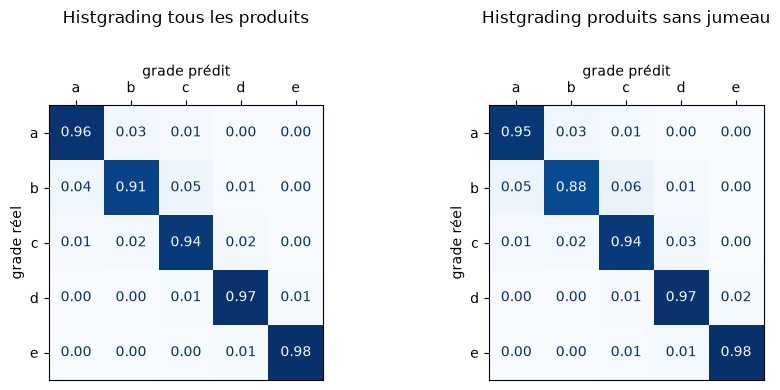

Erreurs : 3 491 sur 91 912 produits (3.8%)


,erreurs,part_des_erreurs
"(réel, prédit)",,
"(b, c)",447,0.128
"(c, d)",427,0.122
"(c, b)",410,0.117
"(b, a)",345,0.099
"(e, d)",317,0.091


,tous les produits,produits sans jumeau
1 cran,2848.0000,2701.000
2 crans,583.0000,547.000
3 crans ou plus,60.0000,58.000
part des erreurs à 1 cran,0.8158,0.817


In [15]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.ml.features import GRADES

BEST = "hist_gradient_boosting_tuned"
best_pipeline = fitted[BEST]   # ajusté sur tout le train à la cellule 9 : aucun réentraînement

y_true_letters = y_test                                   # grades réels (lettres)
y_pred_letters = decode_target(test_predictions[BEST])    # prédictions de la cellule 9, remises en lettres
test_proba = best_pipeline.predict_proba(X_test)          # colonnes dans l'ordre des codes 0 à 4, soit a à e
has_twin_test = fingerprint(X_test).isin(set(train_fingerprints)).to_numpy()
subsets = {"tous les produits": np.ones(len(y_test), dtype=bool), "produits sans jumeau": ~has_twin_test}

# Matrices de confusion normalisées par ligne (chaque case = part des produits du grade réel)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, rows) in zip(axes, subsets.items()):
    cm = confusion_matrix(y_true_letters[rows], y_pred_letters[rows], labels=GRADES, normalize="true")
    assert np.allclose(cm.sum(axis=1), 1), "Lignes qui ne somment pas à 1 : mauvaise normalisation"
    ConfusionMatrixDisplay(cm, display_labels=GRADES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("grade prédit")
    ax.set_ylabel("grade réel")
    ax.set_title(f"Histgrading {title}", pad=30)
plt.tight_layout()
plt.show()

# Les 5 couples (réel, prédit) les plus fréquents parmi les erreurs
is_error = y_true_letters.to_numpy() != y_pred_letters.to_numpy()
pairs = pd.Series(list(zip(y_true_letters[is_error], y_pred_letters[is_error]))).value_counts()
top_pairs = pd.DataFrame({"erreurs": pairs.head(5), "part_des_erreurs": (pairs.head(5) / is_error.sum()).round(3)})
top_pairs.index.name = "(réel, prédit)"
print(f"Erreurs : {is_error.sum():,} sur {len(y_test):,} produits ({is_error.mean():.1%})".replace(",", " "))
display(top_pairs)

# Gravité : écart en nombre de grades, sur tous les produits et sans jumeau
step_gap = np.abs(encode_target(y_true_letters).to_numpy() - test_predictions[BEST].to_numpy())
severity = pd.DataFrame({
    title: {
        "1 cran": np.sum(rows & (step_gap == 1)),
        "2 crans": np.sum(rows & (step_gap == 2)),
        "3 crans ou plus": np.sum(rows & (step_gap >= 3)),
        "part des erreurs à 1 cran": np.sum(rows & (step_gap == 1)) / max(np.sum(rows & (step_gap >= 1)), 1),
    }
    for title, rows in subsets.items()
})
severity

Sur le test, le modèle réglé se trompe sur 3,8 % des produits ; 81,6 % de ces erreurs sont à un seul cran, 1,7 % (60 produits) à trois crans ou plus. Le grade b est le plus difficile (rappel 0,91, 0,88 sans jumeau), confondu surtout avec c et a ; la confusion b/c représente près d'un quart des erreurs. Les autres grades ont un rappel de 0,94 à 0,98. Résultats identiques sans jumeau.

performance par rayon (aisle, équivalent de pnns_groups_1), triée du pire au meilleur

In [16]:
from src.ml.evaluation import METRICS

MIN_RELIABLE = 100   # en dessous de 100 produits du test, les scores d'un rayon sont signalés comme peu fiables

aisle_test = test["aisle"].to_numpy()
rows = []
for aisle in np.unique(aisle_test):
    in_aisle = aisle_test == aisle
    without_twin = in_aisle & ~has_twin_test
    y_true, y_pred = y_true_letters[in_aisle], y_pred_letters[in_aisle]
    rows.append({
        "aisle": aisle,
        "produits": int(in_aisle.sum()),
        "accuracy": METRICS["accuracy"](y_true, y_pred),
        "f1_macro": METRICS["f1_macro"](y_true, y_pred),
        "f1_macro_sans_jumeau": (
            METRICS["f1_macro"](y_true_letters[without_twin], y_pred_letters[without_twin])
            if without_twin.any() else np.nan
        ),
        "part_erreurs_graves": float(np.mean(step_gap[in_aisle] >= 2)),   # erreurs de 2 crans ou plus
        "fiable": bool(in_aisle.sum() >= MIN_RELIABLE),
    })

aisle_table = pd.DataFrame(rows).set_index("aisle").sort_values("f1_macro")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(aisle_table)

,produits,accuracy,f1_macro,f1_macro_sans_jumeau,part_erreurs_graves,fiable
aisle,,,,,,
en-beverages,5848,0.9260,0.7821,0.7536,0.0142,True
en-fruits-and-vegetables,5888,0.9282,0.9108,0.8996,0.0173,True
unknown,7247,0.9325,0.9184,0.9134,0.0261,True
en-salty-snacks,5320,0.9500,0.9409,0.9274,0.0094,True
en-sugary-snacks,18444,0.9863,0.9421,0.9376,0.0008,True
en-cereals-and-potatoes,9535,0.9458,0.9470,0.9378,0.0044,True
en-composite-foods,7117,0.9567,0.9490,0.9456,0.0032,True
en-fats-and-sauces,6085,0.9566,0.9496,0.9388,0.0025,True
en-milk-and-dairy-products,10768,0.9720,0.9571,0.9441,0.0085,True


Performance par rayon (test, modèle réglé) : du pire au meilleur en F1 macro.

- Boissons : rayon le plus difficile, F1 macro 0,78 (0,75 sans jumeau) malgré une accuracy de 0,93 : les grades rares du rayon sont mal prédits. Les boissons relèvent d'un algorithme Nutri-Score à part, que nos features ne distinguent pas.
- Sans rayon (« unknown », 7 247 produits) : plus forte part d'erreurs graves (2,6 % à deux crans ou plus) : sans catégorie, le modèle ne sait pas quelle règle s'applique.
- Fruits et légumes : F1 macro 0,91, teneur en fruits souvent non renseignée.
- Autres rayons : F1 macro de 0,94 à 0,98, le meilleur étant poissons-viandes-œufs (0,98).
- Boissons alcoolisées : 7 produits seulement, scores non interprétables. Rayon hors du périmètre du Nutri-Score, à exclure au prochain export ; aucune prédiction à afficher pour ce rayon.

candidats hésitants entre deux grades voisins (b/c ou d/e), pour l'analyse à la main

In [17]:
MAX_MARGIN = 0.10                                   # écart maximal entre les deux probabilités les plus hautes
HESITATION_PAIRS = {("b", "c"), ("d", "e")}         # couples visés par l'énoncé

# Nom des produits : jointure sur le code avec le Parquet nettoyé le plus récent (diagnostic, jamais une feature)
clean_path = find_input(config.CLEAN_DIR, config.CLEAN_PREFIX, ".parquet")
product_names = pd.read_parquet(clean_path, columns=["code", "product_name"]).set_index("code")["product_name"]

# Les deux grades les plus probables de chaque produit du test, et l'écart entre leurs probabilités
top_two = np.argsort(test_proba, axis=1)[:, ::-1][:, :2]
first_grade, second_grade = np.asarray(GRADES)[top_two[:, 0]], np.asarray(GRADES)[top_two[:, 1]]
margin = test_proba[np.arange(len(test_proba)), top_two[:, 0]] - test_proba[np.arange(len(test_proba)), top_two[:, 1]]

candidates = test[["code", "aisle", "aisle2", *config.CORE_NUTRIENTS, "fiber_100g",
                   "fruits_vegetables_legumes_100g", "nutriscore_score"]].copy()
candidates.insert(1, "product_name", candidates["code"].map(product_names))
candidates["grade_reel"] = y_true_letters.to_numpy()
candidates["grade_predit"] = y_pred_letters.to_numpy()
candidates["hesitation"] = [tuple(sorted(pair)) for pair in zip(first_grade, second_grade)]
candidates["proba_1"] = test_proba.max(axis=1)
candidates["marge"] = margin
candidates["erreur"] = is_error
candidates["a_un_jumeau"] = has_twin_test

candidates = candidates[candidates["hesitation"].isin(HESITATION_PAIRS) & (candidates["marge"] < MAX_MARGIN)]
candidates = candidates.sort_values("marge")

print(f"Fichier nettoyé : {clean_path.name}")
print(f"Produits hésitants (marge < {MAX_MARGIN}) : {len(candidates):,}".replace(",", " "))
print(candidates.groupby(["hesitation", "erreur"]).size().rename("produits").to_string())

display_columns = ["code", "product_name", "aisle2", "grade_reel", "grade_predit", "hesitation", "marge",
                   "nutriscore_score", "erreur", "a_un_jumeau"]
for pair in sorted(HESITATION_PAIRS):
    print(f"\nHésitation {pair[0]}/{pair[1]} : les 10 plus serrées")
    display(candidates[candidates["hesitation"] == pair][display_columns].head(10))

Fichier nettoyé : products_clean_20261113.parquet
Produits hésitants (marge < 0.1) : 411
hesitation  erreur
(b, c)      False     139
            True      128
(d, e)      False      75
            True       69

Hésitation b/c : les 10 plus serrées


,code,product_name,aisle2,grade_reel,grade_predit,hesitation,marge,nutriscore_score,erreur,a_un_jumeau
234932,3492509451327,Panés de blé fromage epinards,unknown,b,c,"(b, c)",0.0002,1,True,False
451147,8718906436206,Biologische spinazieburger,unknown,b,c,"(b, c)",0.0008,2,True,False
420143,8020083168529,Raviolini del plin aux herbes,en-cereals,b,c,"(b, c)",0.0011,2,True,False
338399,4015533026782,Pur jus de cerise acérola,en-fruit-juices,b,b,"(b, c)",0.0013,0,False,False
390662,7300400245005,Frukost,en-bread,b,c,"(b, c)",0.0013,2,True,False
415750,8008811000099,Mini spianata sarda antema,en-bread,b,b,"(b, c)",0.0013,2,False,False
160230,3265479728009,Duo Huile & Beurre,en-fats,c,c,"(b, c)",0.0018,5,False,True
290318,3701002410602,Ricotta Bufflonne,en-cheese,b,b,"(b, c)",0.0022,1,False,False
389748,7035620011788,Cornflakes,en-breakfast-cereals,c,c,"(b, c)",0.0023,3,False,False
1766,00178774,Perfect passion fruit + turmeric,unknown,b,b,"(b, c)",0.0026,1,False,False



Hésitation d/e : les 10 plus serrées


,code,product_name,aisle2,grade_reel,grade_predit,hesitation,marge,nutriscore_score,erreur,a_un_jumeau
49673,2099461010022,Fondue moitie-moitié,en-one-dish-meals,d,e,"(d, e)",0.0001,14,True,False
453476,8847103557138,Mangue séchée au poivre de kampot rouge,en-dried-fruits,e,d,"(d, e)",0.0012,19,True,False
403547,8000590105613,Rusticale ricotta e limone,unknown,d,d,"(d, e)",0.0016,18,False,False
347048,40737133,Choucroute à garnir,en-one-dish-meals,d,d,"(d, e)",0.0019,18,False,False
70941,26020549,Sauce Mexicaine,en-dressings-and-sauces,e,d,"(d, e)",0.0020,19,True,False
48746,20851194,Crackers with Rosemary,en-appetizers,e,d,"(d, e)",0.0028,19,True,False
102919,3144550005508,Piperade de jambon au sel noir fumé,en-one-dish-meals,e,e,"(d, e)",0.0029,19,False,False
440379,8437012780637,Salsa ali oli ecólogica,en-dressings-and-sauces,d,d,"(d, e)",0.0029,18,False,False
32604,0888849005420,Protein bar,unknown,d,d,"(d, e)",0.0051,18,False,False
32500,0880911163618,Aloe,en-sweetened-beverages,d,e,"(d, e)",0.0058,9,True,False


Candidats hésitants : 411 produits du test hésitent entre deux grades voisins avec une marge inférieure à 0,10 (267 en b/c, 144 en d/e), répartis à peu près pour moitié entre erreurs et bonnes prédictions.

Une grande partie des hésitations les plus serrées tombent pile sur un seuil officiel (aliments en général : b jusqu'à 2, c à partir de 3, d jusqu'à 18, e à partir de 19) : produits notés b au score de 2, c au score de 3, d au score de 18, e au score de 19. Pour eux, un seul point de score sépare les deux grades : l'hésitation du modèle reflète une vraie frontière.

Les autres hésitations, loin des seuils de l'algorithme général, désignent des produits notés avec une grille à part (boissons, fromages, matières grasses), que nos features ne distinguent pas.

Cinq produits retenus pour l'analyse à la main, choisis pour couvrir ces deux situations :

| # | Produit | Code | Réel → prédit | Score officiel | Diagnostic présumé (à vérifier) |
|---|---|---|---|---|---|
| 1 | Raviolini del plin aux herbes | 8020083168529 | b → c | 2 | Limite du modèle : score au maximum de b, à un point du seuil de c |
| 2 | Mangue séchée au poivre de kampot rouge | 8847103557138 | e → d | 19 | Limite du modèle : score au minimum de e, à un point du seuil de d |
| 3 | Aloe | 0880911163618 | d → e | 9 | Règle métier absente (boissons) : pour une boisson, d va de 7 à 9 et e commence à 10 ; le modèle ignore que c'est une boisson |
| 4 | Fondue moitié-moitié | 2099461010022 | d → e | 14 | Règle métier absente (fromage) : score au milieu de d, loin de tout seuil ; le fromage a une règle à part (protéines toujours comptées) |
| 5 | Duo Huile & Beurre | 3265479728009 | c → c | 5 | Règle métier absente (matières grasses) : algorithme à part ; bien prédit mais hésitation b/c ; jumeau dans le train |

fiche d'un produit du test, pour l'analyse à la main

In [22]:
from src.ml.features import add_derived_features
from src.ml.features import DERIVED_FEATURES, NUMERIC_FEATURES, add_derived_features

OFF_URL = "https://world.openfoodfacts.org/product/{code}"
test_codes = test["code"].to_numpy()


def show_product(code: str) -> None:
    """Affiche ce que l'on sait d'un produit du test : rayon, score, prédiction, probabilités, jumeau, nutriments."""
    position = np.flatnonzero(test_codes == code)[0]   # rang du produit dans le test, aligné sur test_proba
    row = test.iloc[position]

    print(f"{code} — {product_names.get(code, '(nom inconnu)')}")
    print(f"Fiche Open Food Facts : {OFF_URL.format(code=code)}")
    print(f"Rayon : {row['aisle']} / {row['aisle2']}")
    print(f"Grade réel : {row['nutriscore_grade']} (score officiel {row['nutriscore_score']}) "
          f"-> prédit : {y_pred_letters.iloc[position]}")
    probabilities = pd.Series(test_proba[position], index=GRADES).round(3)
    print(f"Probabilités par grade : {probabilities.to_dict()}")
    print(f"Jumeau exact dans le train : {bool(has_twin_test[position])}")

    print("\nNutriments et features brutes (pour 100 g) :")
    display(row[NUMERIC_FEATURES].to_frame("valeur").T)
    print("Features dérivées :")
    display(add_derived_features(X_test.iloc[[position]])[DERIVED_FEATURES])

explication SHAP d'une hésitation entre deux grades

In [19]:
import shap

shap_preprocessor = best_pipeline.named_steps["preprocessor"]
shap_model = best_pipeline.named_steps["model"]
prepared_names = shap_preprocessor.get_feature_names_out()

# Essai de l'explicateur rapide pour les arbres ; à défaut, explicateur générique sur les probabilités
try:
    explainer = shap.TreeExplainer(shap_model)
    explainer(shap_preprocessor.transform(X_test.iloc[[0]]))   # essai sur un produit
    explainer_kind = "TreeExplainer (contributions en log-cotes)"
except Exception as error:
    print(f"TreeExplainer indisponible ({type(error).__name__}) : explicateur générique, plus lent")
    background = shap_preprocessor.transform(X_train.sample(200, random_state=RANDOM_STATE))
    explainer = shap.Explainer(shap_model.predict_proba, background, feature_names=prepared_names)
    explainer_kind = "Explainer générique (contributions en probabilité)"
print(f"Explicateur : {explainer_kind}")


def explain_product(code: str, top: int = 10) -> None:
    """Features qui poussent un produit du test vers chacun des deux grades entre lesquels le modèle hésite."""
    position = np.flatnonzero(test_codes == code)[0]
    explanation = explainer(shap_preprocessor.transform(X_test.iloc[[position]]))
    values = np.asarray(explanation.values)[0]   # forme attendue : (62 features, 5 grades)

    first, second = np.argsort(test_proba[position])[::-1][:2]   # les deux grades les plus probables
    contributions = pd.DataFrame({
        f"vers {GRADES[first]}": values[:, first],
        f"vers {GRADES[second]}": values[:, second],
    }, index=prepared_names)
    contributions["écart"] = contributions.iloc[:, 0] - contributions.iloc[:, 1]   # > 0 : favorise le 1er grade
    print(f"Hésitation {GRADES[first]} / {GRADES[second]} — features qui départagent le plus :")
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(contributions.reindex(contributions["écart"].abs().sort_values(ascending=False).index).head(top))

Explicateur : TreeExplainer (contributions en log-cotes)


In [23]:
show_product("8020083168529")
explain_product("8020083168529")
show_product("8847103557138")
explain_product("8847103557138")
show_product("0880911163618")
explain_product("0880911163618")
show_product("2099461010022")
explain_product("2099461010022")
show_product("3265479728009")
explain_product("3265479728009")

8020083168529 — Raviolini del plin aux herbes
Fiche Open Food Facts : https://world.openfoodfacts.org/product/8020083168529
Rayon : en-cereals-and-potatoes / en-cereals
Grade réel : b (score officiel 2) -> prédit : c
Probabilités par grade : {'a': 0.017, 'b': 0.491, 'c': 0.492, 'd': 0.0, 'e': 0.0}
Jumeau exact dans le train : False

Nutriments et features brutes (pour 100 g) :


,energy_kcal_100g,fat_100g,saturated_fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,salt_100g,fiber_100g,fruits_vegetables_legumes_100g,nova_group,additives_n
valeur,181.0,3.6,1.8,28.0,1.0,7.0,0.27,NaN,NaN,NaN,NaN


Features dérivées :


,sugars_carbohydrates_ratio,saturated_fat_ratio,fat_energy_ratio,energy_gap_ratio
420143,0.0357,0.5,0.179,0.0499


Hésitation c / b — features qui départagent le plus :


,vers c,vers b,écart
num__salt_100g,0.874,4.650,-3.775
num__sugars_100g,1.146,3.184,-2.038
num__saturated_fat_ratio,0.366,-0.443,0.809
num__saturated_fat_100g,1.499,2.068,-0.569
num__fat_100g,-0.017,0.531,-0.549
num__energy_kcal_100g,0.680,0.142,0.537
num__proteins_100g,0.128,-0.241,0.369
cat__aisle_en-beverages,-0.016,0.304,-0.320
num__fat_energy_ratio,-0.031,0.253,-0.284
num__fiber_100g,0.013,-0.217,0.230


... (20 outputs left out)

Features dérivées :


,sugars_carbohydrates_ratio,saturated_fat_ratio,fat_energy_ratio,energy_gap_ratio
160230,0.0,0.15,1.0,0.0


Hésitation c / b — features qui départagent le plus :


,vers c,vers b,écart
num__salt_100g,1.899,6.038,-4.139
num__sugars_100g,1.165,3.490,-2.324
num__saturated_fat_100g,-0.640,-2.670,2.030
num__saturated_fat_ratio,0.737,2.178,-1.441
num__proteins_100g,0.573,0.072,0.501
num__carbohydrates_100g,0.234,0.687,-0.453
num__fiber_100g,0.090,-0.339,0.429
num__nova_group,0.140,-0.243,0.383
num__fat_energy_ratio,0.254,-0.047,0.300
num__energy_kcal_100g,-0.325,-0.038,-0.287


Produit 1 — Raviolini del plin aux herbes (8020083168529) : réel b, prédit c, probabilités b 0,491 / c 0,492

Nutriments (pour 100 g) : 181 kcal, 3,6 g de lipides dont 1,8 g de saturés, 28 g de glucides dont 1 g de sucres, 7 g de protéines, 0,27 g de sel ; fibres et fruits-légumes non renseignés. Rayon : céréales et pommes de terre.

Calcul officiel (Open Food Facts, algorithme général, pas une boisson) : énergie 2 + sucres 0 + saturés 1 + sel 1 = 4 points défavorables ; protéines 2 points (comptées car moins de 11 points défavorables) ; score 2, soit B, le maximum de B : un seul point de plus donnerait C.

Pourquoi le modèle hésite (SHAP) : les features qui départagent sont des composantes officielles. Le sel et les sucres faibles tirent vers b ; la part de saturés dans les lipides (0,5), l'énergie et les protéines tirent vers c. Les deux camps se compensent presque exactement. Le rayon ne joue quasiment aucun rôle.

Diagnostic : limite du modèle. Le produit est réellement à la frontière b/c : le barème le place à un point du seuil, et le modèle hésite pour les mêmes raisons que le barème. Les fibres non renseignées (imputées) poussent légèrement vers c ; renseignées, elles pourraient faire pencher le barème comme le modèle vers b.

Action : limite à documenter. Pour un produit dont la marge entre deux grades voisins est très faible, afficher les deux grades possibles plutôt qu'une lettre unique.

Produit 2 — Mangue séchée au poivre de kampot rouge (8847103557138) : réel e, prédit d, probabilités d 0,501 / e 0,499

Nutriments (pour 100 g) : 360 kcal, 87 g de glucides dont 69 g de sucres, 1 g de lipides, 0 g de saturés, 2 g de protéines, 0,25 g de sel, 0 g de fibres, 60 % de fruits-légumes. Rayon : fruits et légumes, fruits séchés.

Calcul officiel (Open Food Facts, algorithme général, pas une boisson) : énergie 4 + sucres 15 + saturés 0 + sel 1 = 20 points défavorables ; protéines non comptées (au moins 11 points) ; fruits-légumes 1 point ; score 19, soit E, le minimum de E : un seul point de moins donnerait D.

Pourquoi le modèle hésite (SHAP) : les sucres (69 g) tirent fortement vers e ; la teneur en fruits, l'absence de saturés, le rayon fruits et légumes et le sel faible tirent vers d. Le modèle a appris que les fruits sont plutôt bien notés, mais le séchage concentre le sucre.

Diagnostic : limite du modèle. Le produit est réellement à la frontière d/e, à un point du seuil. Nuance : la teneur en fruits (60 %) n'est pas déclarée ; Open Food Facts l'estime à partir des ingrédients, et elle se trouve elle-même au seuil d'un point supplémentaire : à 61 %, le score serait de 18, soit D. Le grade officiel tient donc à une estimation.

Action : limite à documenter. Signaler comme incertaines les prédictions à faible marge, a fortiori quand une composante du score est estimée et non déclarée.

Produit 3 — Aloe (0880911163618) : réel d, prédit e, probabilités d 0,496 / e 0,502

Nutriments (pour 100 ml) : 36 kcal, 9 g de glucides dont 8 g de sucres, 0 g de lipides, de protéines et de sel ; fibres non renseignées, 0 % de fruits-légumes. Rayon : boissons, boissons sucrées.

Calcul officiel (Open Food Facts) : algorithme des boissons. Énergie 3 points pour seulement 153 kJ (échelle des boissons), sucres 6 points, saturés, sel et édulcorants 0 ; aucun point favorable ; score 9, soit D pour une boisson (D de 7 à 9, E à partir de 10). Pour un aliment, le même score donnerait un C moyen.

Pourquoi le modèle hésite (SHAP) : il mélange deux grilles. Le rayon « boissons » le pousse fortement vers e (indice de la grille des boissons, plus sévère) ; les nutriments, lus avec la logique des aliments (énergie faible, sel nul, sucres modérés), le tirent vers d.

Diagnostic : règle métier absente. Le barème applique aux boissons un algorithme spécifique (échelles plus sévères, composante édulcorants) que nos features ne portent pas ; le modèle ne peut que l'approcher par le rayon. Le produit étant de plus à un point du seuil d/e de cette grille, l'hésitation est maximale.

Action : ajouter une feature « boisson » explicite (dérivée de la catégorie) et le nombre d'édulcorants ; à défaut, documenter la limite pour les boissons, rayon le moins bien prédit (F1 macro 0,78).

Produit 4 — Fondue moitié-moitié (2099461010022) : réel d, prédit e, probabilités d 0,499 / e 0,499

Nutriments (pour 100 g) : 368 kcal, 28 g de lipides dont 17 g de saturés, 0,4 g de glucides et de sucres, 29 g de protéines, 1,6 g de sel ; fibres et fruits-légumes non renseignés. Rayon : plats préparés, plats uniques.

Calcul officiel (Open Food Facts) : le produit est traité comme un fromage. Énergie 4 + sucres 0 + saturés 10 + sel 7 = 21 points défavorables ; pour un fromage, les protéines comptent quel que soit ce total : 7 points ; score 14 (21 − 7), soit D. Avec la règle générale (protéines exclues au-delà de 11 points), le score serait 21, soit E : la prédiction du modèle.

Pourquoi le modèle hésite (SHAP) : les saturés (17 g) le poussent fortement vers e, de même que l'absence du sous-groupe « fromages » ; les sucres quasi nuls et les protéines élevées le tirent vers d. Le modèle a appris la règle du fromage à travers le sous-groupe « en-cheese » ; or cette fondue est rangée en « plats préparés » dans nos données, alors qu'Open Food Facts la traite comme un fromage pour le calcul.

Diagnostic : règle métier absente. La règle spéciale du fromage (protéines toujours comptées) n'est pas portée par nos features ; le modèle l'approche par le rayon, qui ne la signale pas ici.

Action : ajouter une feature « fromage » dérivée des catégories Open Food Facts (celles qui déclenchent la règle), et non du seul rayon ; à défaut, documenter la limite pour les plats à base de fromage rangés hors du rayon fromages.

Produit 5 — Duo Huile & Beurre (3265479728009) : réel c, prédit c, probabilités b 0,499 / c 0,501

Nutriments (pour 100 g) : 900 kcal, 100 g de lipides dont 15 g de saturés, 0 g de glucides, de sucres, de protéines, de sel et de fibres ; NOVA 4, 1 additif. Rayon : matières grasses et sauces, matières grasses. Un jumeau exact dans le train.

Calcul officiel (Open Food Facts) : algorithme des matières grasses, huiles, noix et graines, avec des composantes propres : énergie provenant des saturés (555 kJ, 4 points) au lieu de l'énergie totale, part de saturés dans les lipides (15 %, 1 point) au lieu des saturés en grammes ; sucres et sel 0 ; aucun point favorable ; score 5, soit C (grille des matières grasses : B de -5 à 2, C de 3 à 10). Avec la règle générale, ce produit serait noté E.

Pourquoi le modèle hésite (SHAP) : le sel et les sucres nuls, et surtout la part de saturés dans les lipides (0,15, notre feature dérivée), le tirent vers b ; les saturés en grammes (15 g) le tirent vers c. L'énergie totale (900 kcal) ne pèse presque pas : le modèle a appris qu'elle ne compte pas pour ce type de produit.

Diagnostic : règle métier absente. L'algorithme des matières grasses utilise des composantes que nos features ne portent pas toutes ; le modèle l'approche par le rayon et par le ratio saturés / lipides, qui correspond exactement à l'une de ses composantes. Il trouve le bon grade, mais sans certitude.

Action : ajouter l'énergie provenant des saturés comme feature dérivée (calculable : 37 kJ par gramme de saturés), ce qui donnerait au modèle les deux composantes propres à cette grille.

| # | Produit | Code | Réel → prédit | Score officiel | Diagnostic |
|---|---|---|---|---|---|
| 1 | Raviolini del plin aux herbes | 8020083168529 | b → c | 2 | Limite du modèle : à un point du seuil b/c |
| 2 | Mangue séchée au poivre de kampot rouge | 8847103557138 | e → d | 19 | Limite du modèle : à un point du seuil d/e, teneur en fruits estimée |
| 3 | Aloe | 0880911163618 | d → e | 9 | Règle métier absente : algorithme des boissons |
| 4 | Fondue moitié-moitié | 2099461010022 | d → e | 14 | Règle métier absente : règle du fromage |
| 5 | Duo Huile & Beurre | 3265479728009 | c → c | 5 | Règle métier absente : algorithme des matières grasses |

Aucun des cinq produits ne relève d'une donnée fausse : les hésitations entre grades voisins viennent des frontières du barème et de ses grilles spéciales, alors que les fiches fausses produisaient au TP 14 des erreurs franches et très confiantes.

## Etape ADR

critères mesurés pour l'ADR (taille, latence, réentraînement) des 4 options retenues

In [2]:
# Cellule 15 — Étape 5 : critères mesurés pour l'ADR (taille, latence, réentraînement, test) des 4 options
# Cellule autonome : rechargement des données et réajustement sur tout le train, sans dépendre des cellules précédentes
import tempfile
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier

from src import config
from src.ml.evaluation import evaluate_on_test, fingerprint
from src.ml.features import encode_target, features_and_target, load_features, split_train_test
from src.ml.modeling import RANDOM_STATE, build_pipeline
from src.storage.export_features import EXPORT_PREFIX
from src.utils import find_input

N_JOBS = -1
N_SINGLE_CALLS = 100   # appels unitaires, comme un produit envoyé seul à l'API

# Données : même export, même split figé que le reste du journal
export_path = find_input(config.EXPORTS_DIR, EXPORT_PREFIX, ".parquet")
train, test = split_train_test(load_features(export_path))
X_train, y_train = features_and_target(train)
X_test, y_test = features_and_target(test)
y_train_codes, y_test_codes = encode_target(y_train), encode_target(y_test)
train_fingerprints = fingerprint(X_train)

# Les 4 options de l'ADR, avec exactement les réglages du tableau unique
BEST_PARAMS = {   # recherche Optuna (cellule 7), repris de la cellule 8
    "learning_rate": 0.08574153197420807,
    "max_leaf_nodes": 80,
    "min_samples_leaf": 17,
    "l2_regularization": 0.11400863701127326,
    "class_weight": None,
}
adr_models = {
    "hist_gradient_boosting_tuned": HistGradientBoostingClassifier(
        **BEST_PARAMS, max_iter=1200, early_stopping=True, n_iter_no_change=10, random_state=RANDOM_STATE
    ),
    "hist_gradient_boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "xgboost": XGBClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS),
    "random_forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS),
}

single_product = X_test.iloc[[0]]
rows = []
with tempfile.TemporaryDirectory() as tmp_dir:   # dossier hors du dépôt, supprimé à la sortie du bloc
    for name, model in adr_models.items():
        test_res, _, pipeline = evaluate_on_test(
            build_pipeline(model), X_train, y_train_codes, X_test, y_test_codes, train_fingerprints
        )

        # Taille : pipeline complet (préparation + modèle) sérialisé par joblib
        path = Path(tmp_dir) / f"{name}.joblib"
        joblib.dump(pipeline, path)

        # Latence unitaire : médiane de 100 prédictions d'un seul produit
        durations = []
        for _ in range(N_SINGLE_CALLS):
            start = time.perf_counter()
            pipeline.predict(single_product)
            durations.append(time.perf_counter() - start)

        rows.append({
            "model": name,
            "test_f1_macro": test_res["f1_macro"],
            "test_f1_macro_sans_jumeau": test_res["f1_macro_without_twin"],
            "taille_mo": path.stat().st_size / 1e6,
            "latence_lot_us_par_produit": test_res["predict_time_s"] / len(X_test) * 1e6,
            "latence_unitaire_ms_mediane": float(np.median(durations)) * 1e3,
            "reentrainement_s": test_res["fit_time_s"],
        })
        print(f"{name} : terminé")

print(f"Export : {export_path.name}")
adr_table = pd.DataFrame(rows).set_index("model")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(adr_table)

hist_gradient_boosting_tuned : terminé
hist_gradient_boosting : terminé
xgboost : terminé
random_forest : terminé
Export : features_nutriscore_20261121.parquet


,test_f1_macro,test_f1_macro_sans_jumeau,taille_mo,latence_lot_us_par_produit,latence_unitaire_ms_mediane,reentrainement_s
model,,,,,,
hist_gradient_boosting_tuned,0.9548,0.9434,26.9895,12.9061,35.8362,53.5444
hist_gradient_boosting,0.9233,0.9077,1.8056,2.8820,12.7492,9.2288
xgboost,0.9326,0.9177,2.2753,1.4746,13.0250,21.4426
random_forest,0.9174,0.8933,883.2736,2.9532,24.5460,6.6226
